# FaceScore SSE 消融实验

本 Notebook 复用 `train_compare.ipynb` 已完成的 full SSE 训练记录，确保 `full_sse` 与主实验完全一致。其余变体使用固定的 2335/260 数据划分和同一份冻结 TIPSV2 特征，比较 Sparse Score-field Equilibrium 的关键结构项。每个变体使用相同的损失、优化器、随机种子和早停规则。输出保存在 `outputs/ablation/`，其余消融变体的紧凑权重保存在 `weights/ablation_<variant>.pt`。

In [1]:
import random
import re
from decimal import Decimal,ROUND_HALF_UP
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.stats import spearmanr
from torch.utils.data import DataLoader,Dataset,Subset
from model import SparseLandauScoreField,SparseLandauScoreFieldAblation,SparseLandauScoreFieldWithoutForce,SparseLandauScoreFieldWithoutFreeEnergy,SparseLandauScoreFieldWithoutResidual,SparseLandauScoreFieldWithoutEvidence,SparseLandauScoreFieldTemperatureOne
from others import create_baseline,DistributionLoss
from rating_dataset import RatingDataset
SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP=device.type=='cuda'
NUM_WORKERS=0
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
DATA_DIR=ROOT_DIR/'data'/'face_data'
MASK_DIR=ROOT_DIR/'data'/'face_masks'
VALIDATION_FILE=ROOT_DIR/'data'/'validation_files.txt'
OUTPUT_DIR=ROOT_DIR/'outputs'/'ablation'
MAIN_OUTPUT_DIR=ROOT_DIR/'outputs'/'recent_compare'
WEIGHTS_DIR=ROOT_DIR/'weights'
EPOCHS=200
PATIENCE=40
NLL_PATIENCE=6
MIN_DELTA=1e-5
WARMUP_EPOCHS=4
BATCH_SIZE=128
FEATURE_BATCH=16
LEARNING_RATE=6e-4
WEIGHT_DECAY=0.10
DROPOUT=0.10
EMA_DECAY=0.995
BASE_CONCENTRATION=0.1
PLOT_EPOCHS=50
ABLATION_CONFIGS={'full_sse':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.10},'without_force':{'use_force_field':False,'use_free_energy':True,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.10},'without_free_energy':{'use_force_field':True,'use_free_energy':False,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.10},'without_residual':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':False,'use_evidence':True,'output_temperature':1.10},'without_evidence':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':True,'use_evidence':False,'output_temperature':1.10},'temperature_one':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.00}}
VARIANT_CLASSES={'full_sse':SparseLandauScoreFieldAblation,'without_force':SparseLandauScoreFieldWithoutForce,'without_free_energy':SparseLandauScoreFieldWithoutFreeEnergy,'without_residual':SparseLandauScoreFieldWithoutResidual,'without_evidence':SparseLandauScoreFieldWithoutEvidence,'temperature_one':SparseLandauScoreFieldTemperatureOne}
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
WEIGHTS_DIR.mkdir(parents=True,exist_ok=True)
print('device:',device,'PyTorch:',torch.__version__)


device: cuda PyTorch: 2.10.0+cu128


In [2]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'图像目录不存在: {DATA_DIR.resolve()}')
if not VALIDATION_FILE.is_file():
    raise FileNotFoundError(f'缺少验证集清单: {VALIDATION_FILE.resolve()}')
mask_dir=str(MASK_DIR) if MASK_DIR.is_dir() else None
base_dataset=RatingDataset(str(DATA_DIR),mask_dir=mask_dir,augment=False,repeat=1,image_size=336,soft_target=False)
image_names=[path.name for path in base_dataset.image_paths]
if len(set(image_names))!=len(image_names):
    raise RuntimeError('数据集存在重复文件名')
val_names={Path(line.strip()).name for line in VALIDATION_FILE.read_text(encoding='utf-8-sig').splitlines() if line.strip()}
if not val_names.issubset(set(image_names)):
    raise RuntimeError(f'验证清单中存在缺失图像: {sorted(val_names-set(image_names))[:10]}')
train_ids=[i for i,name in enumerate(image_names) if name not in val_names]
val_ids=[i for i,name in enumerate(image_names) if name in val_names]
if (len(train_ids),len(val_ids))!=(2335,260):
    raise RuntimeError(f'当前划分为 {len(train_ids)}/{len(val_ids)}，预期为 2335/260')
eval_train_dataset=Subset(base_dataset,train_ids)
val_dataset=Subset(base_dataset,val_ids)
def parse_scores(path):
    content=path.with_suffix('.txt').read_text(encoding='utf-8-sig').strip().removeprefix('[').removesuffix(']')
    words=[word for word in re.split(r'[,，\s]+',content) if word]
    scores=[int(max(Decimal(1),min(Decimal(10),Decimal(word))).quantize(Decimal(1),rounding=ROUND_HALF_UP)) for word in words]
    if not scores:
        raise RuntimeError(f'图像缺少评分: {path}')
    return scores
train_counts=[]
train_targets=[]
for idx in train_ids:
    scores=parse_scores(base_dataset.image_paths[idx])
    counts=torch.bincount(torch.tensor(scores,dtype=torch.long)-1,minlength=10).float()
    train_targets.append(counts/counts.sum().clamp_min(1e-8))
    train_counts.append(len(scores))
train_targets=torch.stack(train_targets)
train_counts=torch.tensor(train_counts,dtype=torch.float32)
prior_counts=(train_targets*train_counts.view(-1,1)).sum(dim=0)
prior=prior_counts/train_counts.sum().clamp_min(1.0)
val_counts=[]
val_targets=[]
for idx in val_ids:
    scores=parse_scores(base_dataset.image_paths[idx])
    counts=torch.bincount(torch.tensor(scores,dtype=torch.long)-1,minlength=10).float()
    val_targets.append(counts/counts.sum().clamp_min(1e-8))
    val_counts.append(len(scores))
val_targets=torch.stack(val_targets)
val_counts=torch.tensor(val_counts,dtype=torch.float32)
print('train:',len(train_ids),'validation:',len(val_ids),'single-rating train photos:',int((train_counts==1).sum()))


train: 2335 validation: 260 single-rating train photos: 969


In [3]:
class FeatureCountDataset(Dataset):
    def __init__(self,features,targets,counts):
        self.features=features
        self.targets=targets
        self.counts=counts
    def __len__(self):
        return len(self.features)
    def __getitem__(self,index):
        return self.features[index],self.targets[index],self.counts[index],self.targets[index]
def compute_metrics(probs,targets):
    p=np.asarray(probs,dtype=np.float64)
    y=np.asarray(targets,dtype=np.float64)
    p=np.maximum(p,1e-12)
    p=p/p.sum(axis=1,keepdims=True)
    bins=np.arange(1,11,dtype=np.float64)
    mean_p=p@bins
    mean_y=y@bins
    rho=spearmanr(mean_p,mean_y).statistic
    return {'emd':float(np.sqrt(np.square(np.cumsum(p,axis=1)-np.cumsum(y,axis=1)).mean(axis=1)).mean()),'mae':float(np.abs(mean_p-mean_y).mean()),'nll':float(-(y*np.log(p)).sum(axis=1).mean()),'spearman':float(rho)}
class TrainableEMA:
    def __init__(self,model,decay=0.995):
        self.decay=float(decay)
        self.shadow={name:param.detach().clone() for name,param in model.named_parameters() if param.requires_grad}
        self.backup={}
    @torch.no_grad()
    def update(self,model):
        for name,param in model.named_parameters():
            if param.requires_grad:
                self.shadow[name].lerp_(param.detach(),1.0-self.decay)
    @torch.no_grad()
    def apply(self,model):
        if self.backup:
            raise RuntimeError('EMA 状态尚未恢复')
        for name,param in model.named_parameters():
            if param.requires_grad:
                self.backup[name]=param.detach().clone()
                param.copy_(self.shadow[name])
    @torch.no_grad()
    def restore(self,model):
        for name,param in model.named_parameters():
            if name in self.backup:
                param.copy_(self.backup[name])
        self.backup.clear()
def select_score(metrics):
    return 0.25*metrics['emd']/0.23+0.025*metrics['mae']/1.13+0.45*metrics['nll']/1.84+0.275*(1.0-metrics['spearman'])/0.45
loss_fn=DistributionLoss(prior=prior,alpha=BASE_CONCENTRATION,dm_weight=0.02,ce_weight=0.50,emd_weight=1.00,mean_weight=1.00,rank_weight=0.20,rank_temperature=0.30,rdrop_weight=0.02,tail_weight=0.05,tail_margin=0.02,target_smoothing=0.35,entropy_weight=0.02,count_weight_power=0.25,count_weight_max=1.5,dm_per_rating=True,spread_weight=0.05,field_smooth_weight=0.002).to(device)


In [4]:
class FrozenEncoderTokenAdapter(torch.nn.Module):
    def __init__(self,encoder,input_size,mean,std):
        super().__init__()
        self.encoder=encoder
        self.embed_dim=int(encoder.num_features)
        self.global_only=True
        self.input_size=int(input_size)
        self.register_buffer('mean',mean.detach().clone())
        self.register_buffer('std',std.detach().clone())
    def train(self,mode=True):
        super().train(mode)
        self.encoder.eval()
        return self
tip_encoder=create_baseline('TIPSV2',pretrained=True,freeze_backbone=True,dropout=0.0)
tip_adapter=FrozenEncoderTokenAdapter(tip_encoder.backbone,tip_encoder.input_size,tip_encoder.mean,tip_encoder.std)
feature_extractor=SparseLandauScoreField(pretrained=False,backbone=tip_adapter,dropout=DROPOUT,train_last_stage=False,width=24,prior_mix=0.0,use_entropy=False,use_high_resolution=False,scales=(224,),grid_side=16,use_evidence_head=True,evidence_base=BASE_CONCENTRATION,use_global_token=True).to(device)
feature_extractor.mean.copy_(tip_adapter.mean)
feature_extractor.std.copy_(tip_adapter.std)


tensor([[[[1.]],

         [[1.]],

         [[1.]]]], device='cuda:0')

In [5]:
@torch.inference_mode()
def extract_feature_values(dataset):
    loader=DataLoader(dataset,batch_size=FEATURE_BATCH,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
    chunks=[]
    feature_extractor.eval()
    for batch in loader:
        inputs=batch[0].to(device,non_blocking=True)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            features=feature_extractor.encode_features(inputs)
        chunks.append(features.float().cpu())
    return torch.cat(chunks,dim=0)
train_features=extract_feature_values(eval_train_dataset)
val_features=extract_feature_values(val_dataset)
print('cached TIPSV2 feature shapes:',tuple(train_features.shape),tuple(val_features.shape))


cached TIPSV2 feature shapes: (2335, 768) (260, 768)


In [6]:
def reset_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
def build_variant(name,config):
    model=VARIANT_CLASSES[name](pretrained=False,backbone=tip_adapter,dropout=DROPOUT,train_last_stage=False,width=24,prior_mix=0.0,use_entropy=False,use_high_resolution=False,scales=(224,),grid_side=16,use_evidence_head=True,evidence_base=BASE_CONCENTRATION,use_global_token=True,**config).to(device)
    model.mean.copy_(tip_adapter.mean)
    model.std.copy_(tip_adapter.std)
    model.set_feature_stats(train_features.mean(dim=0),train_features.std(dim=0))
    model.set_prior(prior)
    return model
def train_variant_epoch(model,loader,optimizer,scaler,ema):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    predictions=[]
    labels=[]
    objective_total=0.0
    seen=0
    trainable=[param for param in model.parameters() if param.requires_grad]
    for features,targets,counts,raw_targets in loader:
        features=features.to(device,non_blocking=True).float()
        targets=targets.to(device,non_blocking=True).float()
        counts=counts.to(device,non_blocking=True).float().clamp_min(1.0)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            outputs,concentrations=model.forward_from_features(features,return_pair=True)
            objective=loss_fn(outputs,targets,counts,concentrations)
        if scaler is None:
            objective.backward()
            torch.nn.utils.clip_grad_norm_(trainable,1.0)
            optimizer.step()
            ema.update(model)
        else:
            scaler.scale(objective).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable,1.0)
            previous_scale=scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale()>=previous_scale:
                ema.update(model)
        optimizer.zero_grad(set_to_none=True)
        predictions.append(outputs[0].detach().float().exp().cpu())
        labels.append(raw_targets.detach().float().cpu())
        objective_total+=float(objective.detach())*len(targets)
        seen+=len(targets)
    result=compute_metrics(torch.cat(predictions).numpy(),torch.cat(labels).numpy())
    result['loss']=objective_total/max(1,seen)
    return result
@torch.inference_mode()
def evaluate_variant(model,loader):
    model.eval()
    predictions=[]
    labels=[]
    objective_total=0.0
    seen=0
    for features,targets,counts,raw_targets in loader:
        features=features.to(device,non_blocking=True).float()
        targets=targets.to(device,non_blocking=True).float()
        counts=counts.to(device,non_blocking=True).float().clamp_min(1.0)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=USE_AMP):
            output,concentration=model.forward_from_features(features)
            objective=loss_fn(output,targets,counts,concentration)
        predictions.append(output.detach().float().exp().cpu())
        labels.append(raw_targets.detach().float().cpu())
        objective_total+=float(objective.detach())*len(targets)
        seen+=len(targets)
    result=compute_metrics(torch.cat(predictions).numpy(),torch.cat(labels).numpy())
    result['loss']=objective_total/max(1,seen)
    return result
def save_compact_state(model,path):
    compact={name:tensor.detach().cpu() for name,tensor in model.state_dict().items() if not name.startswith('backbone.')}
    torch.save(compact,path)
def run_variant(name,config):
    reset_seed(SEED)
    model=build_variant(name,config)
    train_dataset_features=FeatureCountDataset(train_features,train_targets,train_counts)
    val_dataset_features=FeatureCountDataset(val_features,val_targets,val_counts)
    train_loader_variant=DataLoader(train_dataset_features,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=USE_AMP)
    val_loader_variant=DataLoader(val_dataset_features,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=USE_AMP)
    decay_parameters=[]
    no_decay_parameters=[]
    prediction_decay_parameters=[]
    prediction_no_decay_parameters=[]
    for parameter_name,parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        is_prediction=any(key in parameter_name.lower() for key in ('head','evidence','global_projection','global_gate'))
        is_no_decay=parameter.ndim<2 or any(key in parameter_name.lower() for key in ('bias','norm','source_scale','source_bias','scale_logits','entropy_log_scale','evidence_gate','local_evidence_logit','global_gate'))
        if is_prediction and is_no_decay:
            prediction_no_decay_parameters.append(parameter)
        elif is_prediction:
            prediction_decay_parameters.append(parameter)
        elif is_no_decay:
            no_decay_parameters.append(parameter)
        else:
            decay_parameters.append(parameter)
    trainable=decay_parameters+no_decay_parameters+prediction_decay_parameters+prediction_no_decay_parameters
    optimizer=torch.optim.AdamW([{'params':decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':WEIGHT_DECAY},{'params':no_decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':0.0},{'params':prediction_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':WEIGHT_DECAY*0.5},{'params':prediction_no_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':0.0}],lr=LEARNING_RATE)
    def schedule_lambda(epoch):
        if epoch<WARMUP_EPOCHS:
            return 0.3+0.7*(epoch+1)/WARMUP_EPOCHS
        schedule_horizon=min(EPOCHS,60)
        progress=min(1.0,(epoch-WARMUP_EPOCHS+1)/max(1,schedule_horizon-WARMUP_EPOCHS))
        return (1e-4/LEARNING_RATE)+(1.0-1e-4/LEARNING_RATE)*0.5*(1.0+np.cos(np.pi*progress))
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=schedule_lambda)
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP) if device.type=='cuda' else None
    ema=TrainableEMA(model,decay=EMA_DECAY)
    checkpoint_path=WEIGHTS_DIR/f'ablation_{name}.pt'
    best_score=float('inf')
    best_row=None
    local_history=[]
    bad_epochs=0
    best_nll=float('inf')
    nll_bad_epochs=0
    for epoch in range(1,EPOCHS+1):
        train_result=train_variant_epoch(model,train_loader_variant,optimizer,scaler,ema)
        ema.apply(model)
        try:
            val_result=evaluate_variant(model,val_loader_variant)
            balance=select_score(val_result)
            improved=np.isfinite(balance) and balance<best_score-MIN_DELTA
            if improved:
                best_score=balance
                best_row={'variant':name,'epoch':epoch,'checkpoint':str(checkpoint_path),**val_result,'balanced':balance}
                save_compact_state(model,checkpoint_path)
        finally:
            ema.restore(model)
        bad_epochs=0 if improved else bad_epochs+1
        nll_improved=np.isfinite(val_result['nll']) and val_result['nll']<best_nll-MIN_DELTA
        best_nll=val_result['nll'] if nll_improved else best_nll
        nll_bad_epochs=0 if nll_improved else nll_bad_epochs+1
        scheduler.step()
        row={'variant':name,'epoch':epoch,'lr':optimizer.param_groups[0]['lr'],'balanced':balance}
        row.update({f'train_{key}':value for key,value in train_result.items()})
        row.update({f'val_{key}':value for key,value in val_result.items()})
        local_history.append(row)
        print(f'{name} Epoch {epoch:03d}/{EPOCHS} | Val EMD={val_result["emd"]:.5f} MAE={val_result["mae"]:.4f} NLL={val_result["nll"]:.4f} Spearman={val_result["spearman"]:.4f} | wait={bad_epochs}/{PATIENCE} nll_wait={nll_bad_epochs}/{NLL_PATIENCE}')
        if bad_epochs>=PATIENCE or nll_bad_epochs>=NLL_PATIENCE:
            print(f'{name} Early stopping')
            break
    if best_row is None:
        raise RuntimeError(f'{name} 没有保存有效权重')
    del model,optimizer,scheduler,ema,train_loader_variant,val_loader_variant,train_dataset_features,val_dataset_features
    if device.type=='cuda':
        torch.cuda.empty_cache()
    return local_history,best_row


开始消融变体: without_force
without_force Epoch 001/200 | Val EMD=0.30569 MAE=1.5517 NLL=2.2962 Spearman=0.2289 | wait=0/40 nll_wait=0/6
without_force Epoch 002/200 | Val EMD=0.30462 MAE=1.5424 NLL=2.2899 Spearman=0.3120 | wait=0/40 nll_wait=0/6
without_force Epoch 003/200 | Val EMD=0.30211 MAE=1.5220 NLL=2.2743 Spearman=0.3547 | wait=0/40 nll_wait=0/6
without_force Epoch 004/200 | Val EMD=0.29803 MAE=1.4905 NLL=2.2486 Spearman=0.3944 | wait=0/40 nll_wait=0/6
without_force Epoch 005/200 | Val EMD=0.29277 MAE=1.4505 NLL=2.2158 Spearman=0.4200 | wait=0/40 nll_wait=0/6
without_force Epoch 006/200 | Val EMD=0.28666 MAE=1.4038 NLL=2.1783 Spearman=0.4372 | wait=0/40 nll_wait=0/6
without_force Epoch 007/200 | Val EMD=0.28014 MAE=1.3569 NLL=2.1380 Spearman=0.4509 | wait=0/40 nll_wait=0/6
without_force Epoch 008/200 | Val EMD=0.27360 MAE=1.3121 NLL=2.0981 Spearman=0.4620 | wait=0/40 nll_wait=0/6
without_force Epoch 009/200 | Val EMD=0.26721 MAE=1.2691 NLL=2.0594 Spearman=0.4723 | wait=0/40 nll_wait=0

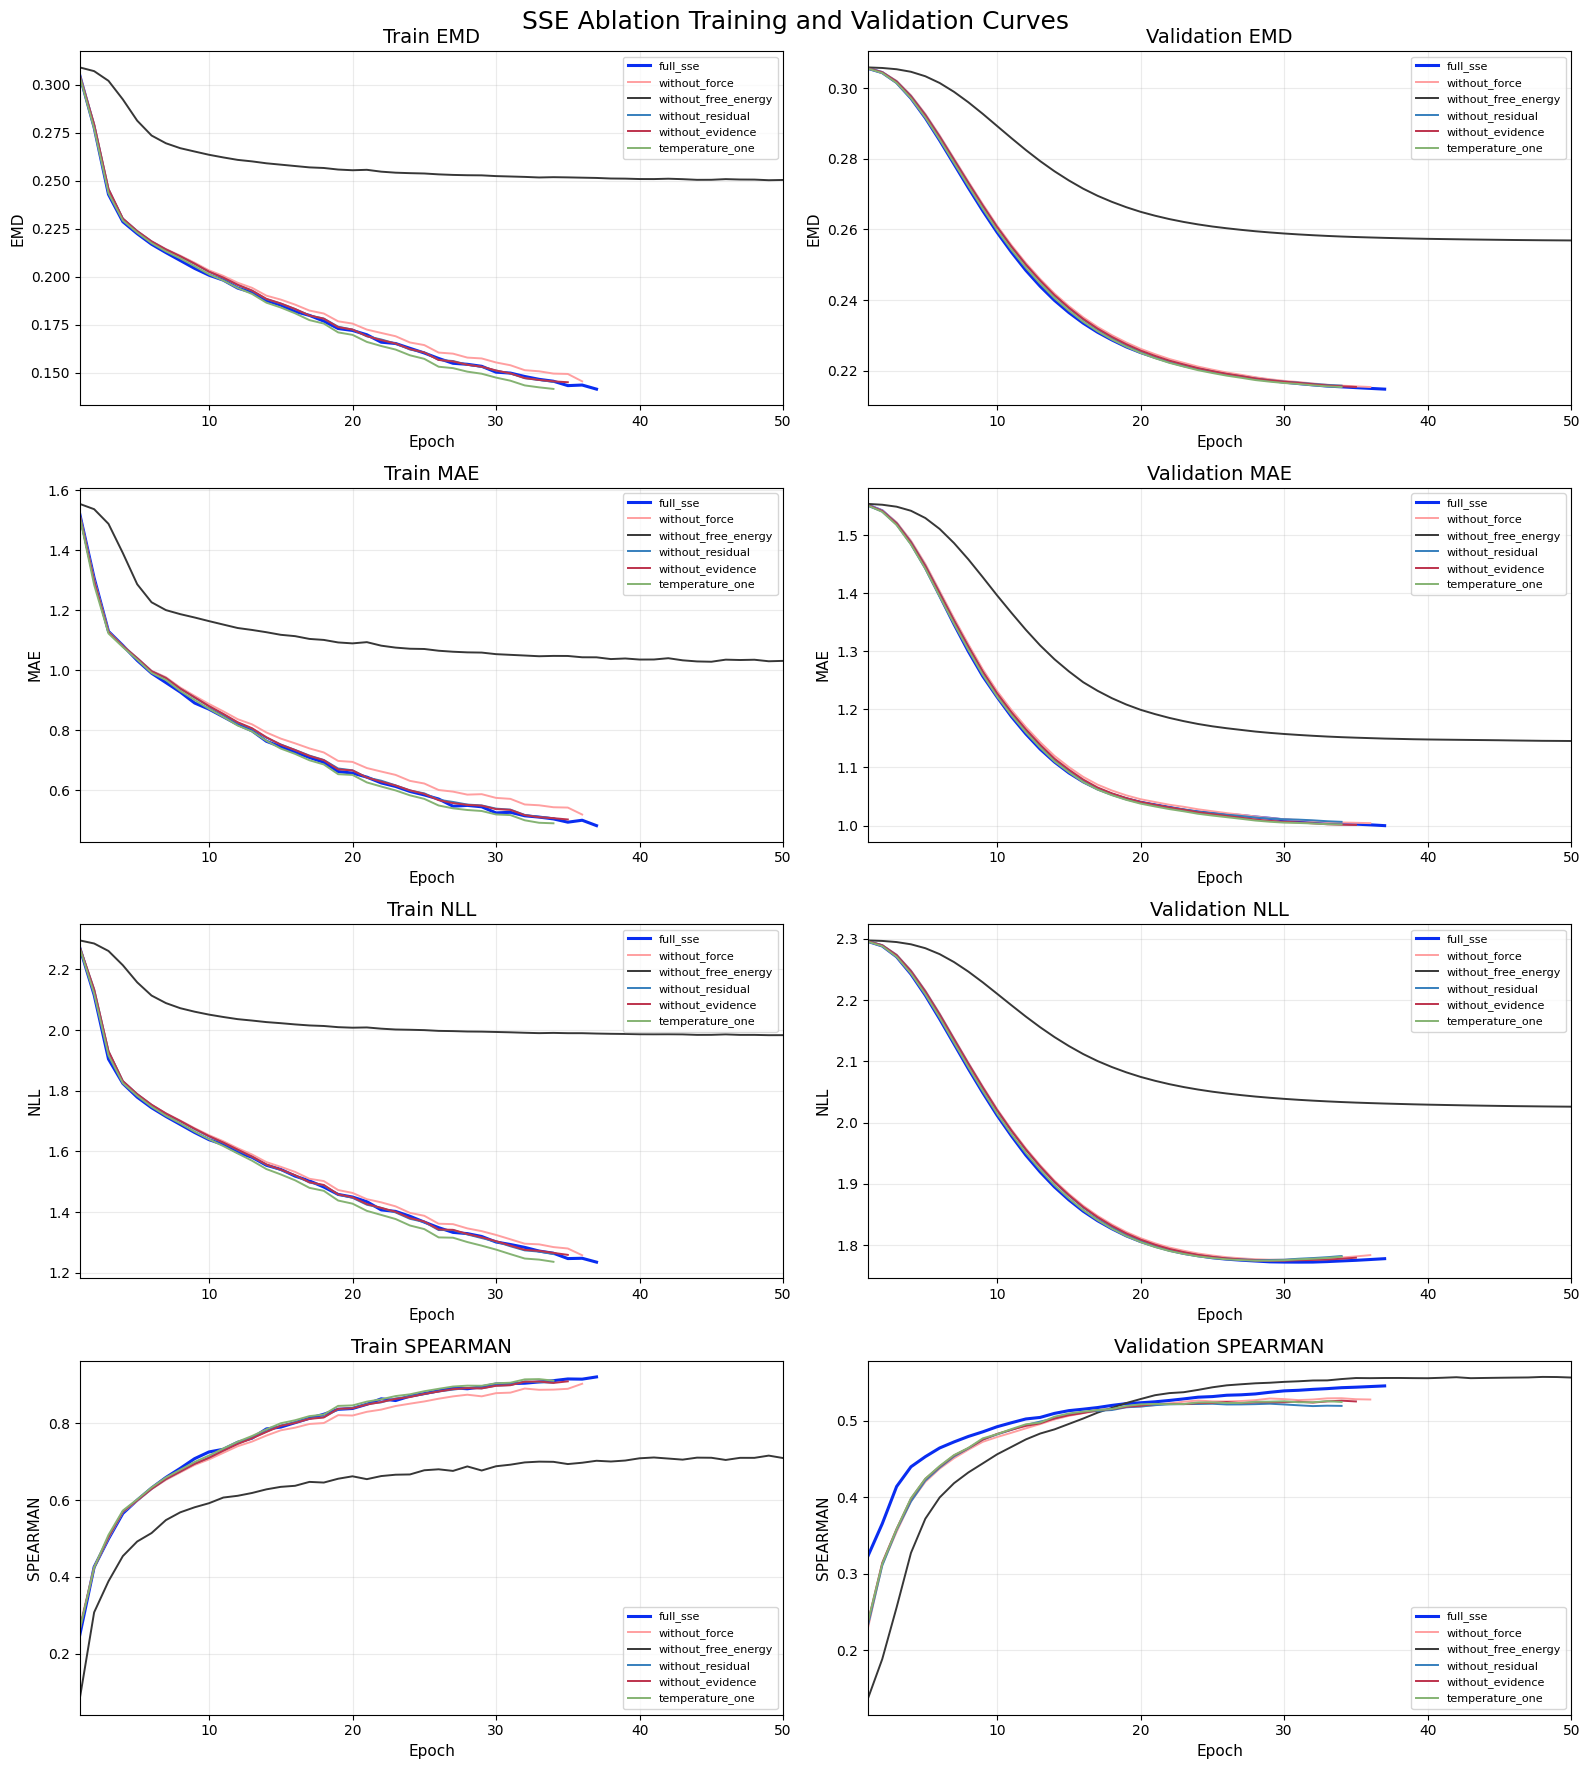

history: D:\MyJupyter\Works\FaceScore\outputs\ablation\history.csv
best metrics: D:\MyJupyter\Works\FaceScore\outputs\ablation\best_metrics.csv
figure: D:\MyJupyter\Works\FaceScore\outputs\ablation\convergence.png


In [7]:
main_history_path=MAIN_OUTPUT_DIR/'history.csv'
main_best_path=MAIN_OUTPUT_DIR/'best_metrics.csv'
if not main_history_path.is_file() or not main_best_path.is_file():
    raise FileNotFoundError('请先运行 train_compare.ipynb，确保 recent_compare/history.csv 和 best_metrics.csv 已存在')
main_history=pd.read_csv(main_history_path)
main_best=pd.read_csv(main_best_path)
required_main_columns=['epoch','train_emd','train_mae','train_nll','train_spearman','val_emd','val_mae','val_nll','val_spearman']
if any(column not in main_history.columns for column in required_main_columns):
    raise RuntimeError('train_compare.ipynb 的 history.csv 缺少必要指标列')
if main_best.empty:
    raise RuntimeError('train_compare.ipynb 的 best_metrics.csv 为空')
main_history.insert(0,'variant','full_sse')
full_best=main_best.iloc[0].to_dict()
full_best['variant']='full_sse'
all_history=main_history.to_dict('records')
all_best=[full_best]
for variant,config in ABLATION_CONFIGS.items():
    if variant=='full_sse':
        continue
    print(f'开始消融变体: {variant}')
    local_history,best_row=run_variant(variant,config)
    all_history.extend(local_history)
    all_best.append(best_row)
    pd.DataFrame.from_records(all_history).to_csv(OUTPUT_DIR/'history.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame.from_records(all_best).to_csv(OUTPUT_DIR/'best_metrics.csv',index=False,encoding='utf-8-sig')
history_frame=pd.DataFrame.from_records(all_history)
summary_frame=pd.DataFrame.from_records(all_best).sort_values('balanced')
print(summary_frame[['variant','epoch','emd','mae','nll','spearman','balanced']].to_string(index=False,float_format=lambda value:f'{value:.5f}'))
COLORS={'full_sse':'#092DF1','without_force':'#FF9FA0','without_free_energy':'#373737','without_residual':'#367FBD','without_evidence':'#BD324C','temperature_one':'#85B373'}
required_metrics=['emd','mae','nll','spearman']
plot_history=history_frame.loc[history_frame['epoch']<=PLOT_EPOCHS].copy()
fig,axes=plt.subplots(4,2,figsize=(16,18))
for row_index,metric in enumerate(required_metrics):
    for variant in ABLATION_CONFIGS:
        table=plot_history.loc[plot_history['variant']==variant].sort_values('epoch')
        axes[row_index,0].plot(table['epoch'],table[f'train_{metric}'],label=variant,color=COLORS[variant],linewidth=2.2 if variant=='full_sse' else 1.4)
        axes[row_index,1].plot(table['epoch'],table[f'val_{metric}'],label=variant,color=COLORS[variant],linewidth=2.2 if variant=='full_sse' else 1.4)
    axes[row_index,0].set_title(f'Train {metric.upper()}',fontsize=14)
    axes[row_index,1].set_title(f'Validation {metric.upper()}',fontsize=14)
    axes[row_index,0].set_xlabel('Epoch',fontsize=11)
    axes[row_index,1].set_xlabel('Epoch',fontsize=11)
    axes[row_index,0].set_ylabel(metric.upper(),fontsize=11)
    axes[row_index,1].set_ylabel(metric.upper(),fontsize=11)
    axes[row_index,0].set_xlim(1,PLOT_EPOCHS)
    axes[row_index,1].set_xlim(1,PLOT_EPOCHS)
    axes[row_index,0].grid(alpha=0.25)
    axes[row_index,1].grid(alpha=0.25)
    axes[row_index,0].legend(fontsize=8)
    axes[row_index,1].legend(fontsize=8)
fig.suptitle('SSE Ablation Training and Validation Curves',fontsize=18)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'convergence.png',dpi=300,bbox_inches='tight')
plt.show()
plt.close(fig)
print('history:',OUTPUT_DIR/'history.csv')
print('best metrics:',OUTPUT_DIR/'best_metrics.csv')
print('figure:',OUTPUT_DIR/'convergence.png')


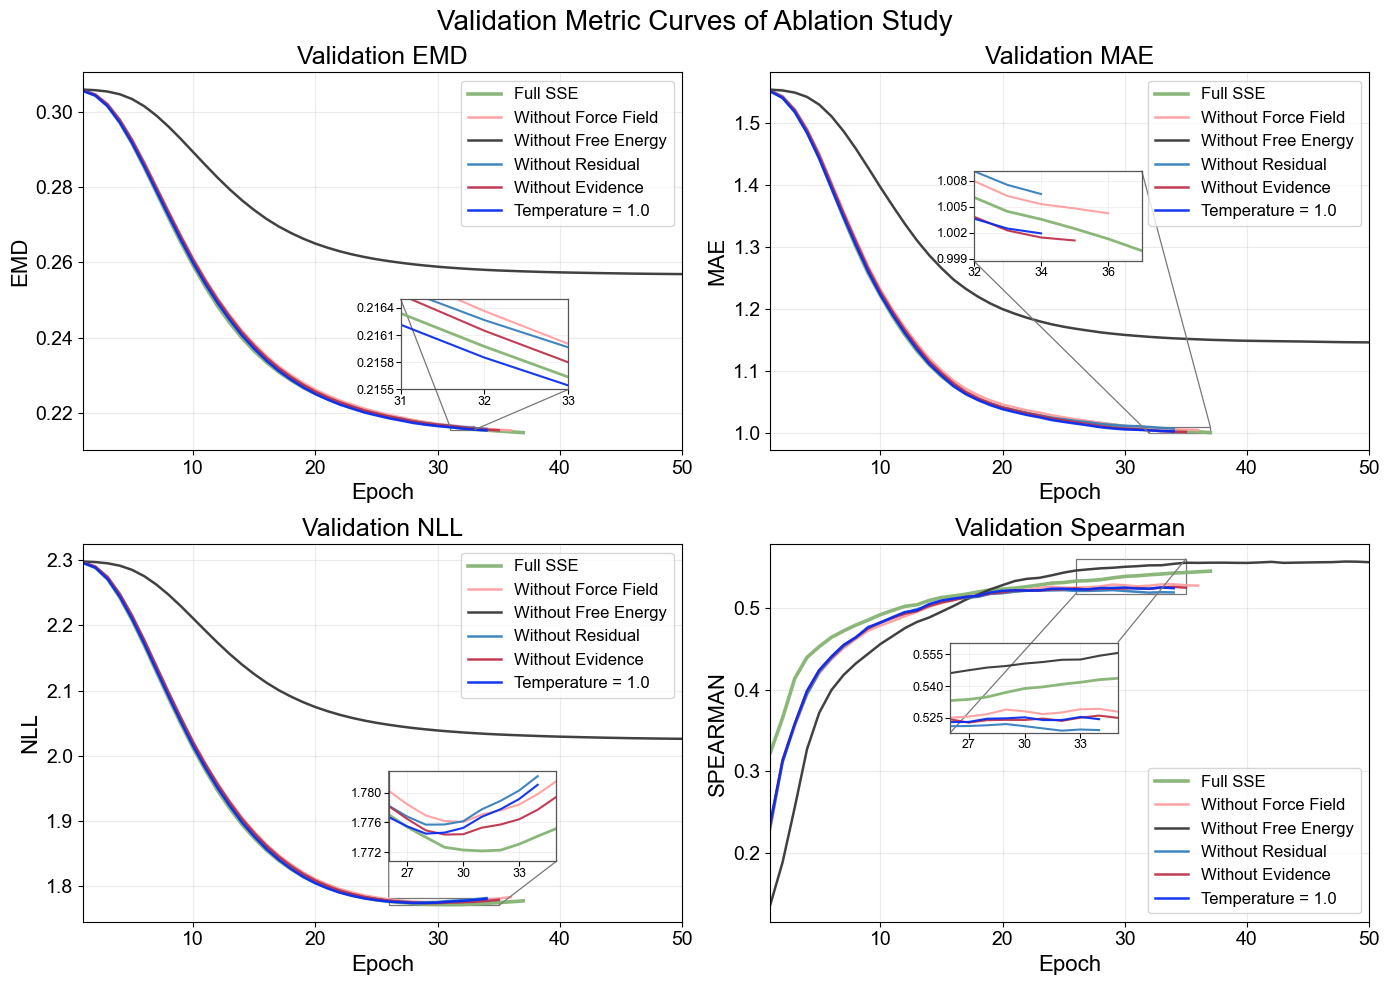

图像已保存到: D:\MyJupyter\Works\FaceScore\outputs\figures\ablation_validation_metric_curves.pdf


In [30]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes,mark_inset
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
OUTPUT_DIR=ROOT_DIR/'outputs'/'ablation'
FIGURE_DIR=ROOT_DIR/'outputs'/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
MAX_EPOCH=50
TITLE_SIZE=18
LABEL_SIZE=16
TICK_SIZE=14
LEGEND_SIZE=12
SUPTITLE_SIZE=20
LINE_WIDTH=1.8
OURS_LINE_WIDTH=2.6

ZOOM_TICK_SIZE=9
ZOOM_LINE_WIDTH=1.5
ZOOM_CONFIG={
    'emd':{'xlim':(31,33),'ylim':(0.2155,0.2165),'position':(0.53,0.16,0.28,0.24),'epochs':10,'nearest':4,'padding':0.15,'loc1':2,'loc2':4},
    'mae':{'xlim':(32,37),'ylim':None,'position':(0.34,0.5,0.28,0.24),'epochs':10,'nearest':4,'padding':0.15,'loc1':1,'loc2':3},
    'nll':{'xlim':None,'ylim':None,'position':(0.51,0.16,0.28,0.24),'epochs':10,'nearest':4,'padding':0.15,'loc1':2,'loc2':4},
    'spearman':{'xlim':None,'ylim':None,'position':(0.3,0.5,0.28,0.24),'epochs':10,'nearest':4,'padding':0.15,'loc1':1,'loc2':3}
}

METHODS=['full_sse','without_force','without_free_energy','without_residual','without_evidence','temperature_one']
METHOD_LABELS={'full_sse':'Full SSE','without_force':'Without Force Field','without_free_energy':'Without Free Energy','without_residual':'Without Residual','without_evidence':'Without Evidence','temperature_one':'Temperature = 1.0'}
PALETTE=['#85B373','#FF9FA0','#373737','#367FBD','#BD324C','#092DF1','#FC2704']
COLORS=dict(zip(METHODS,PALETTE))
METRICS=['emd','mae','nll','spearman']
METRIC_TITLES={'emd':'Validation EMD','mae':'Validation MAE','nll':'Validation NLL','spearman':'Validation Spearman'}
history_path=OUTPUT_DIR/'history.csv'
if not history_path.is_file():
    raise FileNotFoundError(f'消融实验历史记录不存在: {history_path}')
history=pd.read_csv(history_path)
required_columns=['variant','epoch']+[f'val_{metric}' for metric in METRICS]
missing_columns=[column for column in required_columns if column not in history.columns]
if missing_columns:
    raise RuntimeError(f'消融实验历史记录缺少列: {missing_columns}')
history['variant']=history['variant'].astype(str)
history['epoch']=pd.to_numeric(history['epoch'],errors='coerce')
for metric in METRICS:
    history[f'val_{metric}']=pd.to_numeric(history[f'val_{metric}'],errors='coerce')
history=history.loc[history['variant'].isin(METHODS)].copy()
history=history.loc[(history['epoch']>=1)&(history['epoch']<=MAX_EPOCH)].copy()
if history.empty:
    raise RuntimeError('没有找到指定 Epoch 范围内的消融验证数据')
missing_methods=[method for method in METHODS if method not in history['variant'].unique()]
if missing_methods:
    print(f'警告：以下消融变体没有训练记录: {missing_methods}')
last_epochs=history.groupby('variant')['epoch'].max()
plt.rcParams['font.family']='Arial'
plt.rcParams['font.sans-serif']=['Arial']
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['pdf.fonttype']=42
plt.rcParams['ps.fonttype']=42
fig,axes=plt.subplots(2,2,figsize=(14,10))
for axis,metric in zip(axes.ravel(),METRICS):
    column=f'val_{metric}'
    for method in METHODS:
        method_history=history.loc[history['variant']==method].sort_values('epoch')
        if method_history.empty:
            continue
        axis.plot(method_history['epoch'],method_history[column],label=METHOD_LABELS[method],color=COLORS[method],linewidth=OURS_LINE_WIDTH if method=='full_sse' else LINE_WIDTH,alpha=0.95)
    
    cfg=ZOOM_CONFIG[metric]
    if cfg['xlim'] is None:
        zoom_end=int(last_epochs.median())
        zoom_start=max(1,zoom_end-cfg['epochs']+1)
    else:
        zoom_start,zoom_end=cfg['xlim']
    zoom_latest={}
    for method in METHODS:
        method_history=history.loc[(history['variant']==method)&(history['epoch']>=zoom_start)&(history['epoch']<=zoom_end),['epoch',column]].dropna().sort_values('epoch')
        if not method_history.empty:
            zoom_latest[method]=float(method_history.iloc[-1][column])
    if zoom_latest:
        reference_value=zoom_latest.get('full_sse',float(pd.Series(zoom_latest).median()))
        focus_methods=sorted(zoom_latest,key=lambda method:abs(zoom_latest[method]-reference_value))[:cfg['nearest']]
        focus_values=history.loc[history['variant'].isin(focus_methods)&(history['epoch']>=zoom_start)&(history['epoch']<=zoom_end),column].dropna()
        if not focus_values.empty and zoom_start<zoom_end:
            zoom_axis=axis.inset_axes(cfg['position'])
            for method in METHODS:
                method_history=history.loc[history['variant']==method].sort_values('epoch')
                if method_history.empty:
                    continue
                zoom_axis.plot(method_history['epoch'],method_history[column],color=COLORS[method],linewidth=ZOOM_LINE_WIDTH+0.5 if method=='full_sse' else ZOOM_LINE_WIDTH,alpha=0.95)
            zoom_axis.set_xlim(zoom_start,zoom_end)
            if cfg['ylim'] is None:
                y_min=float(focus_values.min())
                y_max=float(focus_values.max())
                y_padding=max((y_max-y_min)*cfg['padding'],1e-6)
                zoom_axis.set_ylim(y_min-y_padding,y_max+y_padding)
            else:
                zoom_axis.set_ylim(*cfg['ylim'])
            zoom_axis.tick_params(axis='both',labelsize=ZOOM_TICK_SIZE,pad=1)
            zoom_axis.xaxis.set_major_locator(MaxNLocator(nbins=4,integer=True))
            zoom_axis.yaxis.set_major_locator(MaxNLocator(nbins=4))
            zoom_axis.grid(alpha=0.2,linewidth=0.6)
            zoom_axis.set_facecolor('white')
            for spine in zoom_axis.spines.values():
                spine.set_linewidth(0.9)
                spine.set_edgecolor('#555555')
            mark_inset(axis,zoom_axis,loc1=cfg['loc1'],loc2=cfg['loc2'],fc='none',ec='#777777',lw=0.9)
    axis.set_title(METRIC_TITLES[metric],fontsize=TITLE_SIZE,fontfamily='Arial')
    axis.set_xlabel('Epoch',fontsize=LABEL_SIZE,fontfamily='Arial')
    axis.set_ylabel(metric.upper(),fontsize=LABEL_SIZE,fontfamily='Arial')
    axis.tick_params(axis='both',labelsize=TICK_SIZE)
    axis.grid(alpha=0.25,linewidth=0.8)
    axis.legend(fontsize=LEGEND_SIZE,frameon=True)
    axis.set_xlim(1,MAX_EPOCH)
fig.suptitle('Validation Metric Curves of Ablation Study',fontsize=SUPTITLE_SIZE,fontfamily='Arial')
fig.tight_layout()
figure_path=FIGURE_DIR/'ablation_validation_metric_curves.pdf'
fig.savefig(figure_path,dpi=600,bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'图像已保存到: {figure_path}')


In [31]:

import gc
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader
SEEDS=[42,123,2026,3407,777]
REPEAT_VARIANTS=['without_force','without_free_energy','without_residual','without_evidence','temperature_one']
SKIP_EXISTING=True
REQUIRED_NAMES=['device','USE_AMP','OUTPUT_DIR','MAIN_OUTPUT_DIR','WEIGHTS_DIR','train_features','val_features','train_targets','val_targets','train_counts','val_counts','prior','tip_adapter','loss_fn','ABLATION_CONFIGS','VARIANT_CLASSES','build_variant','train_variant_epoch','evaluate_variant','FeatureCountDataset','TrainableEMA','select_score','reset_seed','save_compact_state','EPOCHS','PATIENCE','NLL_PATIENCE','MIN_DELTA','WARMUP_EPOCHS','BATCH_SIZE','LEARNING_RATE','WEIGHT_DECAY','EMA_DECAY']
missing_names=[name for name in REQUIRED_NAMES if name not in globals()]
if missing_names:
    raise RuntimeError(f'请先运行train_ablation.ipynb的前6个代码单元格，缺少: {missing_names}')
SEED_METRICS_PATH=OUTPUT_DIR/'seed_best_metrics.csv'
SEED_HISTORY_PATH=OUTPUT_DIR/'seed_history.csv'
MAIN_SEED_METRICS_PATH=MAIN_OUTPUT_DIR/'seed_best_metrics.csv'
if not MAIN_SEED_METRICS_PATH.is_file():
    raise FileNotFoundError(f'主对比多种子训练记录不存在: {MAIN_SEED_METRICS_PATH}')
if len(train_features)!=2335 or len(val_features)!=260:
    raise RuntimeError(f'固定划分数量异常: {len(train_features)}/{len(val_features)}')
if len(SEEDS)!=len(set(SEEDS)):
    raise ValueError('随机种子不能重复')
if not all(name in ABLATION_CONFIGS and name in VARIANT_CLASSES for name in REPEAT_VARIANTS):
    raise RuntimeError('消融变体配置或模型类不完整')
WEIGHTS_DIR.mkdir(parents=True,exist_ok=True)
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
main_seed_log=pd.read_csv(MAIN_SEED_METRICS_PATH)
if not {'method','seed','best_epoch','val_emd','val_mae','val_nll','val_spearman'}.issubset(main_seed_log.columns):
    raise RuntimeError('主对比seed_best_metrics.csv缺少必要列')
main_seed_log['seed']=pd.to_numeric(main_seed_log['seed'],errors='raise').astype(int)
main_seed_log['method']=main_seed_log['method'].astype(str)
for seed in SEEDS:
    full_checkpoint=WEIGHTS_DIR/f'ours_{seed}.pt'
    matching=main_seed_log.loc[(main_seed_log['method']=='ours')&(main_seed_log['seed']==seed)]
    if not full_checkpoint.is_file() or len(matching)!=1:
        raise RuntimeError(f'缺少完整Full SSE主实验权重或训练记录: {full_checkpoint}')
    if 'checkpoint' in matching.columns and Path(str(matching.iloc[0]['checkpoint'])).name!=full_checkpoint.name:
        raise RuntimeError(f'Full SSE权重与主实验训练记录不一致: {full_checkpoint.name}')
with torch.no_grad():
    full_reference=build_variant('full_sse',ABLATION_CONFIGS['full_sse'])
    full_reference_state=full_reference.state_dict()
full_state=torch.load(WEIGHTS_DIR/f'ours_{SEEDS[0]}.pt',map_location='cpu',weights_only=True)
if set(full_state.keys())!=set(full_reference_state.keys()):
    raise RuntimeError('Full SSE与主实验ours的state_dict结构不同，不能直接复用，请核实model.py版本')
for name,value in full_reference_state.items():
    if name.startswith('backbone.') and not torch.equal(value.detach().cpu(),full_state[name]):
        raise RuntimeError(f'本次消融使用的冻结TIPSV2与主实验权重不同: {name}')
del full_reference,full_reference_state,full_state
if device.type=='cuda':
    torch.cuda.empty_cache()
def upsert_seed_csv(path,records,key_columns):
    new_frame=pd.DataFrame.from_records(records)
    if path.is_file():
        previous=pd.read_csv(path)
        new_frame=pd.concat([previous,new_frame],ignore_index=True)
    new_frame=new_frame.drop_duplicates(subset=key_columns,keep='last')
    new_frame.to_csv(path,index=False,encoding='utf-8-sig')
def train_ablation_seed(variant,seed,checkpoint_path):
    reset_seed(seed)
    model=build_variant(variant,ABLATION_CONFIGS[variant])
    train_dataset=FeatureCountDataset(train_features,train_targets,train_counts)
    val_dataset=FeatureCountDataset(val_features,val_targets,val_counts)
    train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=USE_AMP)
    val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=USE_AMP)
    decay_parameters=[]
    no_decay_parameters=[]
    prediction_decay_parameters=[]
    prediction_no_decay_parameters=[]
    for name,param in model.named_parameters():
        if not param.requires_grad:
            continue
        is_prediction=any(key in name.lower() for key in ('head','evidence','global_projection','global_gate'))
        is_no_decay=param.ndim<2 or any(key in name.lower() for key in ('bias','norm','source_scale','source_bias','scale_logits','entropy_log_scale','evidence_gate','local_evidence_logit','global_gate'))
        if is_prediction and is_no_decay:
            prediction_no_decay_parameters.append(param)
        elif is_prediction:
            prediction_decay_parameters.append(param)
        elif is_no_decay:
            no_decay_parameters.append(param)
        else:
            decay_parameters.append(param)
    optimizer=torch.optim.AdamW([{'params':decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':WEIGHT_DECAY},{'params':no_decay_parameters,'lr':LEARNING_RATE*0.5,'weight_decay':0.0},{'params':prediction_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':WEIGHT_DECAY*0.5},{'params':prediction_no_decay_parameters,'lr':LEARNING_RATE*1.3,'weight_decay':0.0}],lr=LEARNING_RATE)
    def schedule_lambda(epoch):
        if epoch<WARMUP_EPOCHS:
            return 0.3+0.7*(epoch+1)/WARMUP_EPOCHS
        schedule_horizon=min(EPOCHS,60)
        progress=min(1.0,(epoch-WARMUP_EPOCHS+1)/max(1,schedule_horizon-WARMUP_EPOCHS))
        return (1e-4/LEARNING_RATE)+(1.0-1e-4/LEARNING_RATE)*0.5*(1.0+np.cos(np.pi*progress))
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=schedule_lambda)
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP) if device.type=='cuda' else None
    ema=TrainableEMA(model,decay=EMA_DECAY)
    best_score=float('inf')
    best_row=None
    temp_path=checkpoint_path.with_suffix('.tmp')
    if temp_path.exists():
        temp_path.unlink()
    best_nll=float('inf')
    bad_epochs=0
    nll_bad_epochs=0
    history=[]
    stop_reason='max_epochs'
    for epoch in range(1,EPOCHS+1):
        train_result=train_variant_epoch(model,train_loader,optimizer,scaler,ema)
        ema.apply(model)
        try:
            val_result=evaluate_variant(model,val_loader)
            score=select_score(val_result)
            improved=np.isfinite(score) and score<best_score-MIN_DELTA
            if improved:
                best_score=float(score)
                best_row={'variant':variant,'seed':seed,'best_epoch':epoch,'checkpoint':checkpoint_path.name,'checkpoint_format':'compact_without_backbone','val_emd':val_result['emd'],'val_mae':val_result['mae'],'val_nll':val_result['nll'],'val_spearman':val_result['spearman'],'balanced':best_score}
                save_compact_state(model,temp_path)
        finally:
            ema.restore(model)
        bad_epochs=0 if improved else bad_epochs+1
        nll_improved=np.isfinite(val_result['nll']) and val_result['nll']<best_nll-MIN_DELTA
        best_nll=float(val_result['nll']) if nll_improved else best_nll
        nll_bad_epochs=0 if nll_improved else nll_bad_epochs+1
        scheduler.step()
        epoch_row={'variant':variant,'seed':seed,'epoch':epoch,'lr':optimizer.param_groups[0]['lr'],'balanced':float(score)}
        epoch_row.update({f'train_{key}':value for key,value in train_result.items()})
        epoch_row.update({f'val_{key}':value for key,value in val_result.items()})
        history.append(epoch_row)
        if bad_epochs>=PATIENCE:
            stop_reason='score_patience'
        elif nll_bad_epochs>=NLL_PATIENCE:
            stop_reason='nll_patience'
        if epoch==1 or epoch%5==0 or stop_reason!='max_epochs':
            print(f'{variant} seed={seed} epoch={epoch:03d} EMD={val_result["emd"]:.5f} MAE={val_result["mae"]:.5f} NLL={val_result["nll"]:.5f} Spearman={val_result["spearman"]:.5f} best={best_row["best_epoch"] if best_row else 0}',flush=True)
        if stop_reason!='max_epochs':
            break
    if best_row is None:
        raise RuntimeError(f'{variant} seed={seed}未产生有限的最佳验证指标')
    temp_path.replace(checkpoint_path)
    best_row['stop_epoch']=epoch
    best_row['stop_reason']=stop_reason
    del model,optimizer,scheduler,scaler,ema,train_loader,val_loader,train_dataset,val_dataset
    gc.collect()
    if device.type=='cuda':
        torch.cuda.empty_cache()
    return best_row,history
for seed in SEEDS:
    main_row=main_seed_log.loc[(main_seed_log['method']=='ours')&(main_seed_log['seed']==seed)].iloc[0]
    full_record={'variant':'full_sse','seed':seed,'best_epoch':int(main_row['best_epoch']),'stop_epoch':int(main_row['stop_epoch']) if 'stop_epoch' in main_row and pd.notna(main_row['stop_epoch']) else np.nan,'stop_reason':main_row['stop_reason'] if 'stop_reason' in main_row else 'recorded_in_main','checkpoint':f'ours_{seed}.pt','checkpoint_format':'full','val_emd':main_row['val_emd'],'val_mae':main_row['val_mae'],'val_nll':main_row['val_nll'],'val_spearman':main_row['val_spearman'],'balanced':main_row['balanced'] if 'balanced' in main_row else np.nan}
    upsert_seed_csv(SEED_METRICS_PATH,[full_record],['variant','seed'])
for variant in REPEAT_VARIANTS:
    for seed in SEEDS:
        checkpoint_path=WEIGHTS_DIR/f'{variant}_{seed}.pt'
        recorded=False
        if SEED_METRICS_PATH.is_file():
            current_log=pd.read_csv(SEED_METRICS_PATH)
            recorded=bool(((current_log['variant']==variant)&(current_log['seed'].astype(int)==seed)&(current_log['checkpoint']==checkpoint_path.name)).any())
        if checkpoint_path.is_file():
            if SKIP_EXISTING and recorded:
                print(f'跳过已有训练: {checkpoint_path.name}')
                continue
            raise FileExistsError(f'{checkpoint_path}已存在但无法安全跳过，请检查权重和日志，代码不会覆盖旧权重')
        print(f'开始训练: {variant} | seed={seed}',flush=True)
        best_record,seed_history=train_ablation_seed(variant,seed,checkpoint_path)
        upsert_seed_csv(SEED_METRICS_PATH,[best_record],['variant','seed'])
        upsert_seed_csv(SEED_HISTORY_PATH,seed_history,['variant','seed','epoch'])
        print(f'已保存: {checkpoint_path.name} | 最佳Epoch={best_record["best_epoch"]}',flush=True)
result_table=pd.read_csv(SEED_METRICS_PATH)
result_table=result_table.loc[result_table['variant'].isin(['full_sse']+REPEAT_VARIANTS)&result_table['seed'].isin(SEEDS)]
completed=result_table.groupby('variant')['seed'].nunique()
if any(completed.get(variant,0)!=len(SEEDS) for variant in ['full_sse']+REPEAT_VARIANTS):
    raise RuntimeError('部分消融变体未完成5个训练种子，请检查训练记录')
print(result_table.groupby('variant')[['val_emd','val_mae','val_nll','val_spearman']].agg(['mean','std']).round(5).to_string())
print('完成：5种子×6种变体；Full SSE复用原始权重，新训练25份消融权重。')
print(f'权重目录：{WEIGHTS_DIR}')
print(f'最佳指标：{SEED_METRICS_PATH}')
print(f'训练历史：{SEED_HISTORY_PATH}')


开始训练: without_force | seed=42
without_force seed=42 epoch=001 EMD=0.30569 MAE=1.55167 NLL=2.29619 Spearman=0.22886 best=1
without_force seed=42 epoch=005 EMD=0.29277 MAE=1.45047 NLL=2.21576 Spearman=0.41999 best=5
without_force seed=42 epoch=010 EMD=0.26112 MAE=1.23144 NLL=2.02230 Spearman=0.47856 best=10
without_force seed=42 epoch=015 EMD=0.23831 MAE=1.10069 NLL=1.88370 Spearman=0.50623 best=15
without_force seed=42 epoch=020 EMD=0.22619 MAE=1.04539 NLL=1.81134 Spearman=0.51847 best=20
without_force seed=42 epoch=025 EMD=0.22029 MAE=1.02472 NLL=1.78299 Spearman=0.52511 best=25
without_force seed=42 epoch=030 EMD=0.21711 MAE=1.01085 NLL=1.77605 Spearman=0.52807 best=30
without_force seed=42 epoch=035 EMD=0.21555 MAE=1.00481 NLL=1.78151 Spearman=0.52792 best=34
without_force seed=42 epoch=036 EMD=0.21537 MAE=1.00425 NLL=1.78365 Spearman=0.52754 best=34
已保存: without_force_42.pt | 最佳Epoch=34
开始训练: without_force | seed=123
without_force seed=123 epoch=001 EMD=0.30569 MAE=1.55187 NLL=2.296